#**Importing Necessary Libraries**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import cv2
from google.colab.patches import cv2_imshow
import os
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, InputLayer, BatchNormalization
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


#**Pre-Processing**


**Training Data**

---



In [ ]:
# Generate data paths with labels
def load_train():    # For Training data
  filepaths = []
  label = []
  path = "/content/gdrive/MyDrive/DS Mini Project/Images/Training"
  folders = os.listdir(path)       # all the folders present in that Training folder

  for files in folders:        # iterate inside that path
    folder_path = os.path.join(path, files)       # create the path for sub-folders inside i.e. ['glioma', 'pituitary', 'meningioma', 'notumor']
    filelist = os.listdir(folder_path)   # all the sub-folders inside

    for fl in filelist:          # iterate over the sub-folders ['glioma', 'pituitary', 'meningioma', 'notumor']
      fpath = os.path.join(folder_path, fl)     # create path for all the files inside the folders
      filepaths.append(fpath)      # append the paths into a list
      label.append(files)    # append the labels

  # Concatenate data paths with labels
  Fpath_series = pd.Series(filepaths, name= 'filepaths')
  label_series = pd.Series(label, name='labels')
  df = pd.concat([Fpath_series, label_series], axis= 1)      # verically

  return df

In [ ]:
train_df = load_train()

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2870 entries, 0 to 2869
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   filepaths  2870 non-null   object
 1   labels     2870 non-null   object
dtypes: object(2)
memory usage: 45.0+ KB


In [ ]:
train_df.head(10)

,filepaths,labels
0,/content/gdrive/MyDrive/DS Mini Project/Images...,pituitary_tumor
1,/content/gdrive/MyDrive/DS Mini Project/Images...,pituitary_tumor
2,/content/gdrive/MyDrive/DS Mini Project/Images...,pituitary_tumor
3,/content/gdrive/MyDrive/DS Mini Project/Images...,pituitary_tumor
4,/content/gdrive/MyDrive/DS Mini Project/Images...,pituitary_tumor
5,/content/gdrive/MyDrive/DS Mini Project/Images...,pituitary_tumor
6,/content/gdrive/MyDrive/DS Mini Project/Images...,pituitary_tumor
7,/content/gdrive/MyDrive/DS Mini Project/Images...,pituitary_tumor
8,/content/gdrive/MyDrive/DS Mini Project/Images...,pituitary_tumor
9,/content/gdrive/MyDrive/DS Mini Project/Images...,pituitary_tumor


In [ ]:
train_df.tail(10)

,filepaths,labels
2860,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
2861,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
2862,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
2863,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
2864,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
2865,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
2866,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
2867,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
2868,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
2869,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor


In [ ]:
train_df.shape

(2870, 2)

**Testing data**

---



In [ ]:
# Generate data paths with labels
def load_test():    # For Testing data
  filepaths = []
  label = []
  path = "/content/gdrive/MyDrive/DS Mini Project/Images/Testing"
  folders = os.listdir(path)       # all the folders present in that Testing folder

  for files in folders:        # iterate inside that path
    folder_path = os.path.join(path, files)       # create the path for sub-folders inside i.e. ['glioma', 'pituitary', 'meningioma', 'notumor']
    filelist = os.listdir(folder_path)   # all the sub-folders inside

    for fl in filelist:          # iterate over the sub-folders ['glioma', 'pituitary', 'meningioma', 'notumor']
      fpath = os.path.join(folder_path, fl)     # create path for all the files inside the folders
      filepaths.append(fpath)      # append the paths into a list
      label.append(files)    # append the labels

  # Concatenate data paths with labels
  Fpath_series = pd.Series(filepaths, name= 'filepaths')
  label_series = pd.Series(label, name='labels')
  df = pd.concat([Fpath_series, label_series], axis= 1)      # verically

  return df

In [ ]:
test_df = load_test()

In [ ]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 394 entries, 0 to 393
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   filepaths  394 non-null    object
 1   labels     394 non-null    object
dtypes: object(2)
memory usage: 6.3+ KB


In [ ]:
test_df.head(10)

,filepaths,labels
0,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
1,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
2,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
3,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
4,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
5,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
6,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
7,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
8,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor
9,/content/gdrive/MyDrive/DS Mini Project/Images...,glioma_tumor


In [ ]:
test_df.tail(10)

,filepaths,labels
384,/content/gdrive/MyDrive/DS Mini Project/Images...,no_tumor
385,/content/gdrive/MyDrive/DS Mini Project/Images...,no_tumor
386,/content/gdrive/MyDrive/DS Mini Project/Images...,no_tumor
387,/content/gdrive/MyDrive/DS Mini Project/Images...,no_tumor
388,/content/gdrive/MyDrive/DS Mini Project/Images...,no_tumor
389,/content/gdrive/MyDrive/DS Mini Project/Images...,no_tumor
390,/content/gdrive/MyDrive/DS Mini Project/Images...,no_tumor
391,/content/gdrive/MyDrive/DS Mini Project/Images...,no_tumor
392,/content/gdrive/MyDrive/DS Mini Project/Images...,no_tumor
393,/content/gdrive/MyDrive/DS Mini Project/Images...,no_tumor


In [ ]:
test_df.shape

(394, 2)

#**Analysis/Visualization**

In [ ]:
# Experiment 1 - No graphs, cleaning
train_df.isna().sum()

filepaths    0
labels       0
dtype: int64

In [ ]:
test_df.isna().sum()

filepaths    0
labels       0
dtype: int64

In [ ]:
train_df.describe()

,filepaths,labels
count,2870,2870
unique,2870,4
top,/content/gdrive/MyDrive/DS Mini Project/Images...,pituitary_tumor
freq,1,827


In [ ]:
# For Training
train_df['labels'].value_counts()

pituitary_tumor     827
glioma_tumor        826
meningioma_tumor    822
no_tumor            395
Name: labels, dtype: int64

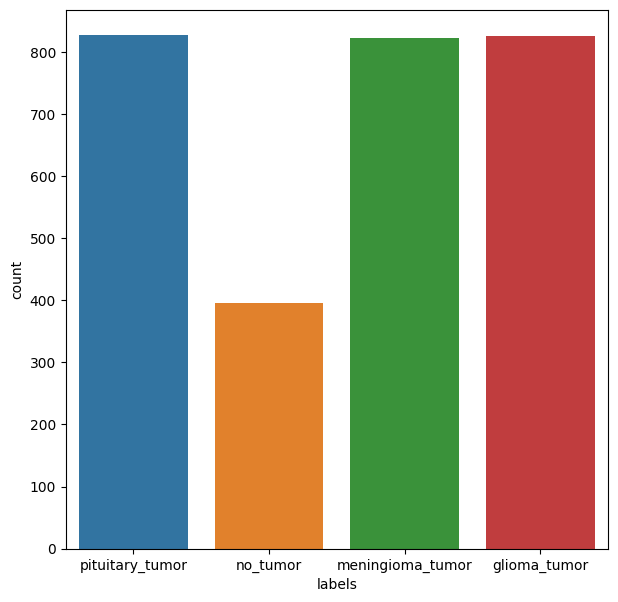

In [ ]:
plt.figure(figsize=(7,7))
sns.countplot(data = train_df, x = train_df['labels'])
plt.show()

In [ ]:
# For Testing
test_df['labels'].value_counts()

meningioma_tumor    115
no_tumor            105
glioma_tumor        100
pituitary_tumor      74
Name: labels, dtype: int64

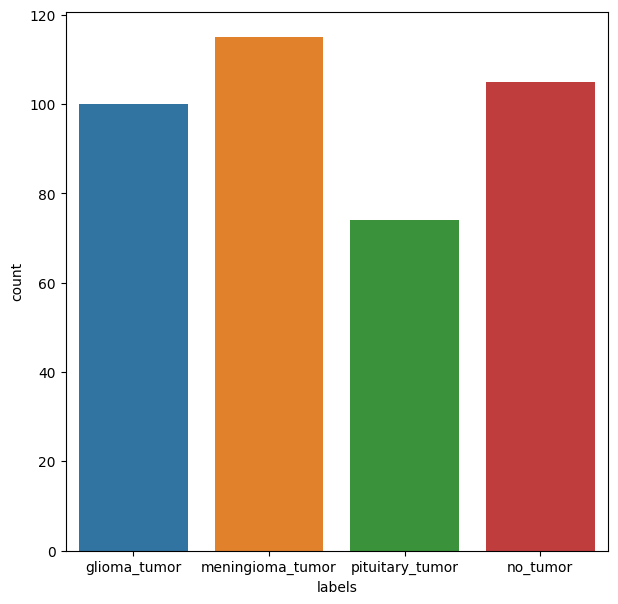

In [ ]:
plt.figure(figsize=(7,7))
sns.countplot(data = test_df, x = test_df['labels'])
plt.show()

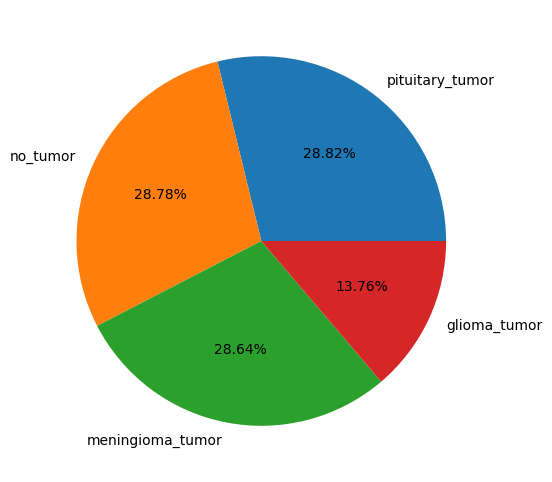

In [ ]:
plt.figure(figsize=(10,6))
plt.pie(train_df['labels'].value_counts(), labels=list(train_df['labels'].unique()), autopct='%0.2f%%')
plt.show()

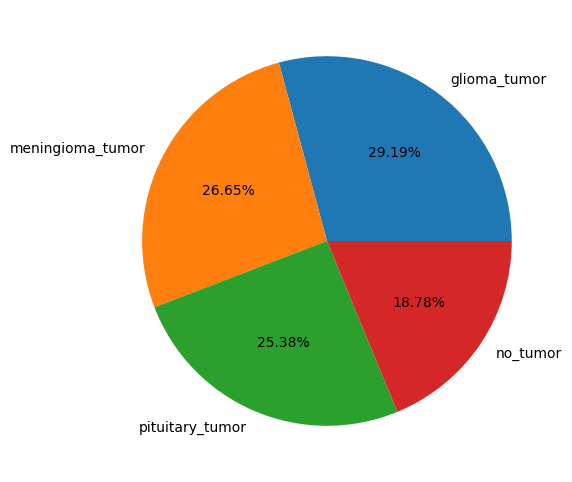

In [ ]:
plt.figure(figsize=(10,6))
plt.pie(test_df['labels'].value_counts(), labels=list(test_df['labels'].unique()), autopct='%0.2f%%')
plt.show()

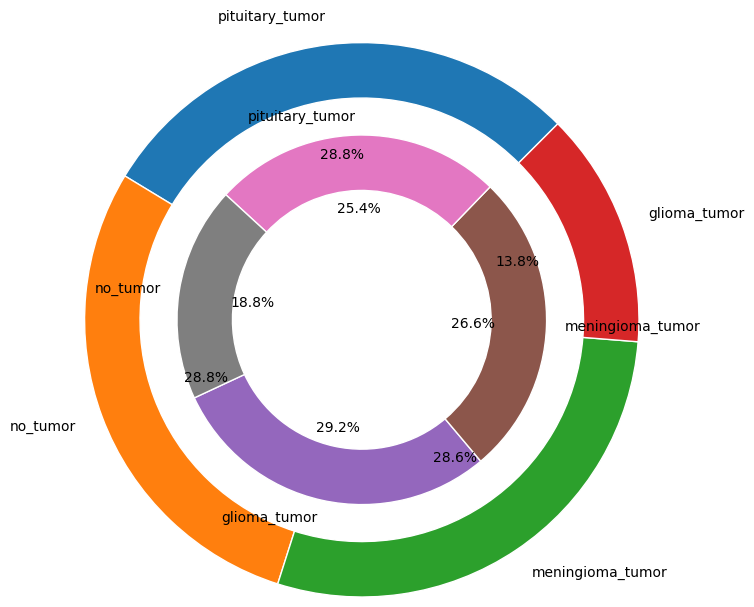

In [ ]:
fig, ax = plt.subplots(figsize=(10,6))
size = 0.3

ax.pie(train_df['labels'].value_counts(), radius=1.5,
       labels=list(train_df['labels'].unique()),
       autopct='%1.1f%%', startangle=45,
       wedgeprops=dict(width=size, edgecolor='w'))

ax.pie(test_df['labels'].value_counts(), radius=1,
       labels=list(test_df['labels'].unique()),
       autopct='%1.1f%%', startangle=205,
       wedgeprops=dict(width=size, edgecolor='w'))

plt.show()

#**Building the Model**

In [ ]:
# Model Initialization
model = Sequential()

In [ ]:
#Layer 1
model.add(Conv2D(32, (3,3), input_shape=(512, 512, 3), padding='same', activation='relu'))
#Adding a MaxPooling layer
model.add(MaxPooling2D(pool_size=(2,2)))

#Layer 2
model.add(Conv2D(32,(3,3), padding='same', activation='relu'))
#Adding a MaxPooling layer
model.add(MaxPooling2D(pool_size=(2,2)))

#Layer 3
model.add(Conv2D(32,(2,2), padding='same', activation='relu'))
#Adding a MaxPooling layer
model.add(MaxPooling2D(pool_size=(2,2)))

#Flattening the layer
model.add(Flatten())

#**Fully Connected Layers**

In [ ]:
# Adding a Dense Layer
model.add(Dense(units=256, activation='relu'))
# Adding dropout
model.add(Dropout(0.5))

# Final output layer
model.add(Dense(units=4, activation='softmax'))

**Optimizer and Loss function**

In [ ]:
# Compiling CNN using Adam Optimizer
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 512, 512, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 256, 256, 32)      0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 256, 256, 32)      9248      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 128, 128, 32)      0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 128, 128, 32)      4128      
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 64, 64, 32)        0

#**Training**
*Training data: 5712*

*Testing + Validation data: 1311 (787 + 524)*

In [ ]:
from keras.preprocessing.image import ImageDataGenerator
# Creating a data generator to progressively load images and normalize all values by 255
train_gen = ImageDataGenerator(rescale=1./255, shear_range=0.2, zoom_range=0.2, horizontal_flip=True)
test_gen = ImageDataGenerator(rescale=1./255)

# Setting Training data generator's source directory
# Setting the target size to 64x64 as the model as the model input layer expects 32x32 (kernel/filter size) images
train_data = train_gen.flow_from_dataframe(train_df, x_col = 'filepaths', y_col= 'labels', target_size=(512, 512), batch_size=64, class_mode='categorical', color_mode='rgb')

# Setting Testing data generator's source directory
test_data = test_gen.flow_from_dataframe(test_df, x_col = 'filepaths', y_col= 'labels', target_size=(512, 512), batch_size=64, class_mode='categorical', color_mode='rgb')

# Setting Validation data generator's source directory
# valid_data = data_gen.flow_from_dataframe(valid_df, target_size=(64,64), batch_size=32, class_mode='catergorical')


Found 2870 validated image filenames belonging to 4 classes.
Found 394 validated image filenames belonging to 4 classes.


In [ ]:
classes = train_data.class_indices
print(classes)

{'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}


In [ ]:
# from keras import utils, callbacks
# earlystopping = callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=5, restore_best_weights = True)

In [ ]:
# data_gen.fit(train_data)
# history = model.fit(train_data, epochs=20, callbacks = [earlystopping], validation_data=test_data)

In [ ]:
# Fitting the model
model.fit(train_data, steps_per_epoch=int(2870/64), epochs=30, validation_data=test_data, validation_steps=int(394/64))

Epoch 1/10
44/44 [==============================] - 1026s 23s/step - loss: 1.5794 - accuracy: 0.4109 - val_loss: 1.4147 - val_accuracy: 0.3516
Epoch 2/10
44/44 [==============================] - 189s 4s/step - loss: 0.9763 - accuracy: 0.5841 - val_loss: 1.6217 - val_accuracy: 0.4635
Epoch 3/10
44/44 [==============================] - 190s 4s/step - loss: 0.9145 - accuracy: 0.5994 - val_loss: 2.4659 - val_accuracy: 0.4141
Epoch 4/10
44/44 [==============================] - 186s 4s/step - loss: 0.7950 - accuracy: 0.6686 - val_loss: 2.5797 - val_accuracy: 0.3958
Epoch 5/10
44/44 [==============================] - 188s 4s/step - loss: 0.7731 - accuracy: 0.6736 - val_loss: 1.9277 - val_accuracy: 0.4870
Epoch 6/10
44/44 [==============================] - 189s 4s/step - loss: 0.6906 - accuracy: 0.7063 - val_loss: 2.1877 - val_accuracy: 0.4922
Epoch 7/10
44/44 [==============================] - 190s 4s/step - loss: 0.6586 - accuracy: 0.7138 - val_loss: 2.4915 - val_accuracy: 0.4609
Epoch 8/10


In [ ]:
model.fit(train_data, steps_per_epoch=int(2870/64), epochs=10, validation_data=test_data, validation_steps=int(394/64))

Epoch 1/10
44/44 [==============================] - 196s 4s/step - loss: 0.5624 - accuracy: 0.7651 - val_loss: 4.0259 - val_accuracy: 0.4036
Epoch 2/10
44/44 [==============================] - 198s 5s/step - loss: 0.5512 - accuracy: 0.7694 - val_loss: 3.2802 - val_accuracy: 0.4375
Epoch 3/10
44/44 [==============================] - 191s 4s/step - loss: 0.5042 - accuracy: 0.7926 - val_loss: 3.8237 - val_accuracy: 0.3854
Epoch 4/10
44/44 [==============================] - 192s 4s/step - loss: 0.5060 - accuracy: 0.7897 - val_loss: 3.5242 - val_accuracy: 0.4714
Epoch 5/10
44/44 [==============================] - 190s 4s/step - loss: 0.4975 - accuracy: 0.7983 - val_loss: 3.3618 - val_accuracy: 0.5078
Epoch 6/10
44/44 [==============================] - 189s 4s/step - loss: 0.4501 - accuracy: 0.8111 - val_loss: 3.6501 - val_accuracy: 0.4818
Epoch 7/10
44/44 [==============================] - 194s 4s/step - loss: 0.4581 - accuracy: 0.8093 - val_loss: 4.1761 - val_accuracy: 0.5078
Epoch 8/10
44

In [ ]:
model.fit(train_data, steps_per_epoch=int(2870/64), epochs=7, validation_data=test_data, validation_steps=int(394/64))

Epoch 1/7
44/44 [==============================] - 190s 4s/step - loss: 0.4173 - accuracy: 0.8300 - val_loss: 3.5208 - val_accuracy: 0.5729
Epoch 2/7
44/44 [==============================] - 195s 4s/step - loss: 0.3964 - accuracy: 0.8425 - val_loss: 3.3038 - val_accuracy: 0.5703
Epoch 3/7
44/44 [==============================] - 186s 4s/step - loss: 0.3805 - accuracy: 0.8403 - val_loss: 3.2962 - val_accuracy: 0.5990
Epoch 4/7
44/44 [==============================] - 189s 4s/step - loss: 0.3749 - accuracy: 0.8550 - val_loss: 3.7473 - val_accuracy: 0.5990
Epoch 5/7
44/44 [==============================] - 187s 4s/step - loss: 0.3433 - accuracy: 0.8585 - val_loss: 3.8734 - val_accuracy: 0.5677
Epoch 6/7
44/44 [==============================] - 187s 4s/step - loss: 0.3671 - accuracy: 0.8525 - val_loss: 4.3054 - val_accuracy: 0.5156
Epoch 7/7
44/44 [==============================] - 191s 4s/step - loss: 0.3303 - accuracy: 0.8642 - val_loss: 4.2907 - val_accuracy: 0.5443


In [ ]:
model.fit(train_data, steps_per_epoch=int(2870/64), epochs=5, validation_data=test_data, validation_steps=int(394/64))

Epoch 1/5
44/44 [==============================] - 189s 4s/step - loss: 0.3216 - accuracy: 0.8696 - val_loss: 5.0236 - val_accuracy: 0.5521
Epoch 2/5
44/44 [==============================] - 190s 4s/step - loss: 0.3369 - accuracy: 0.8703 - val_loss: 4.5705 - val_accuracy: 0.5495
Epoch 3/5
44/44 [==============================] - 189s 4s/step - loss: 0.2984 - accuracy: 0.8835 - val_loss: 4.0221 - val_accuracy: 0.5859
Epoch 4/5
44/44 [==============================] - 187s 4s/step - loss: 0.2891 - accuracy: 0.8856 - val_loss: 4.4191 - val_accuracy: 0.6042
Epoch 5/5
44/44 [==============================] - 190s 4s/step - loss: 0.2973 - accuracy: 0.8870 - val_loss: 4.7171 - val_accuracy: 0.5469


In [ ]:
# 30-32 epochs

In [ ]:
model.save('./brain_tumor_classifier.h5')
model.save_weights('./brain_tumor_classifier_weights.h5')

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


#**Sample Images**

In [ ]:
gt1 = cv2.imread('/content/gdrive/MyDrive/DS Mini Project/Images/Training/glioma_tumor/gg (1).jpg')
mt1 = cv2.imread('/content/gdrive/MyDrive/DS Mini Project/Images/Training/meningioma_tumor/m (100).jpg')
nt1 = cv2.imread('/content/gdrive/MyDrive/DS Mini Project/Images/Training/no_tumor/1.jpg')
pt1 = cv2.imread('/content/gdrive/MyDrive/DS Mini Project/Images/Training/pituitary_tumor/p (10).jpg')

(-0.5, 511.5, 511.5, -0.5)

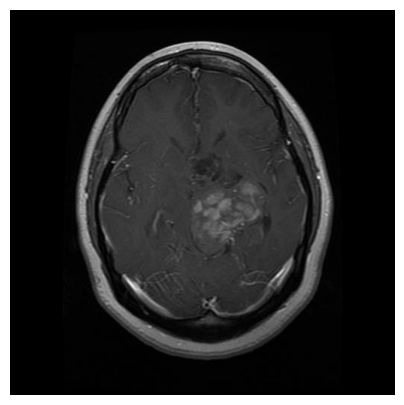

In [ ]:
plt.rcParams["figure.figsize"] = (5,5)
plt.imshow(gt1)
plt.axis('off')

(-0.5, 511.5, 511.5, -0.5)

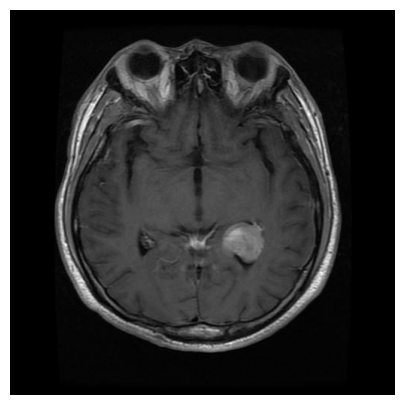

In [ ]:
plt.rcParams["figure.figsize"] = (5,5)
plt.imshow(mt1)
plt.axis('off')

(-0.5, 349.5, 349.5, -0.5)

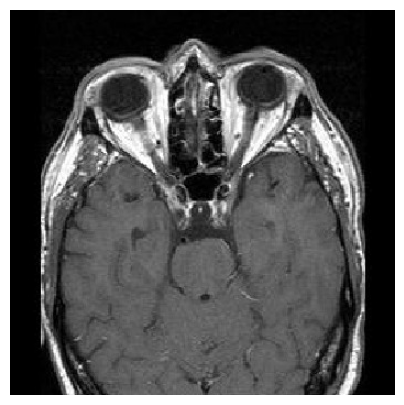

In [ ]:
plt.rcParams["figure.figsize"] = (5,5)
plt.imshow(nt1)
plt.axis('off')

(-0.5, 511.5, 511.5, -0.5)

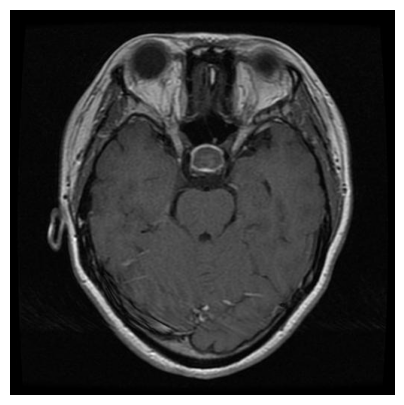

In [ ]:
plt.rcParams["figure.figsize"] = (5,5)
plt.imshow(pt1)
plt.axis('off')

#**Prediction**

In [ ]:
preds = model.predict(test_data)

y_pred = np.argmax(preds , axis = 1)

7/7 [==============================] - 4s 557ms/step


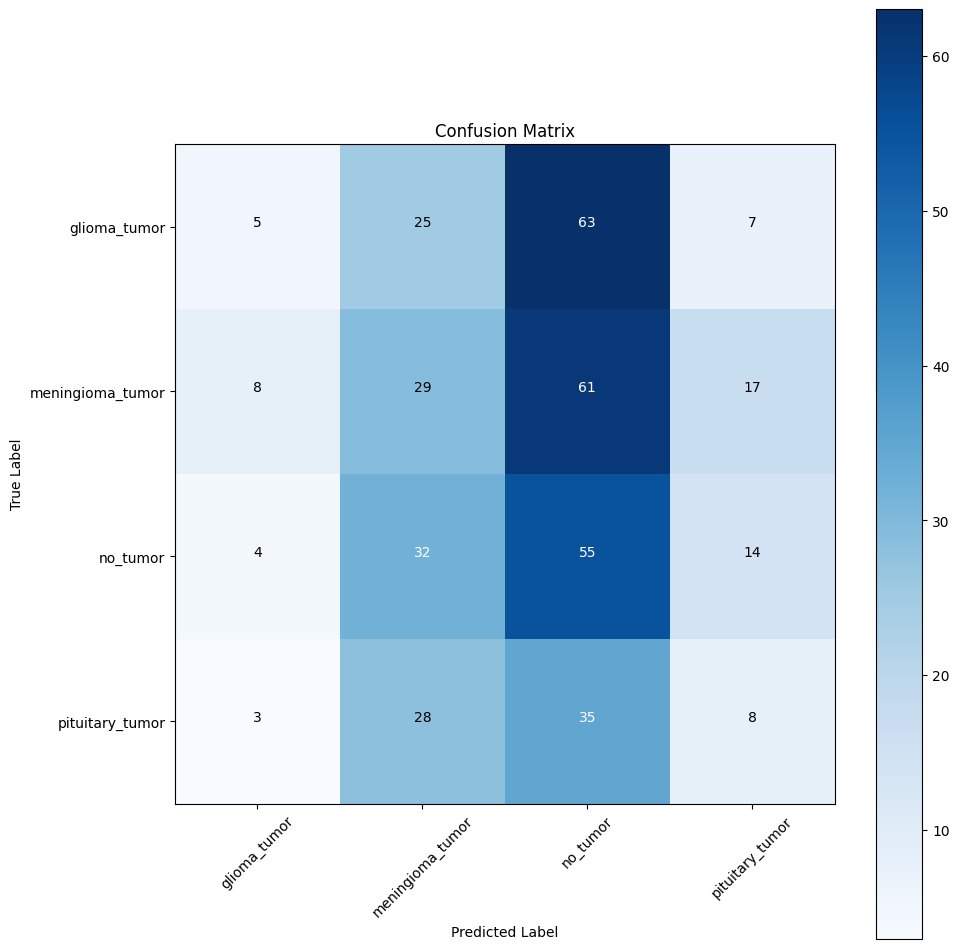

In [ ]:
import itertools
g_dict = test_data.class_indices
classes = list(g_dict)

# Confusion matrix
cm = confusion_matrix(test_data.classes, y_pred)

plt.figure(figsize= (10, 10))
plt.imshow(cm, interpolation= 'nearest', cmap= plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()

tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation= 45)
plt.yticks(tick_marks, classes)


thresh = cm.max() / 2.
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, cm[i, j], horizontalalignment= 'center', color= 'white' if cm[i, j] > thresh else 'black')

plt.tight_layout()
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

plt.show()

#**Testing**

In [ ]:
from keras.utils import load_img, img_to_array

In [ ]:
from keras.models import load_model
model = load_model('/content/brain_tumor_classifier.h5')

OSError: ignored

In [ ]:
class_list = list(classes)
class_list

['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']

In [ ]:
test_image = load_img('/content/gdrive/MyDrive/DS Mini Project/Images/Training/no_tumor/1.jpg', target_size = (512, 512))

test_image = img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)
pred1 = model.predict(test_image)

print(pred1[0])
print(np.argmax(pred1[0]))
print(class_list[np.argmax(pred1[0])])

1/1 [==============================] - 0s 31ms/step
[0. 0. 1. 0.]
2
no_tumor


In [ ]:
test_image = load_img('/content/gdrive/MyDrive/DS Mini Project/Images/Training/meningioma_tumor/m (100).jpg', target_size = (512, 512))

test_image = img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)
pred1 = model.predict(test_image)

print(pred1[0])
print(np.argmax(pred1[0]))
print(class_list[np.argmax(pred1[0])])

1/1 [==============================] - 0s 69ms/step
[0. 1. 0. 0.]
1
meningioma_tumor


In [ ]:
test_image = load_img('/content/gdrive/MyDrive/DS Mini Project/Images/Training/glioma_tumor/gg (134).jpg', target_size = (512, 512))

test_image = img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)
pred1 = model.predict(test_image)

print(pred1[0])
print(np.argmax(pred1[0]))
print(class_list[np.argmax(pred1[0])])

1/1 [==============================] - 0s 33ms/step
[0. 0. 1. 0.]
2
no_tumor


In [ ]:
test_image = load_img('/content/gdrive/MyDrive/DS Mini Project/Images/Training/pituitary_tumor/p (141).jpg', target_size = (512, 512))

test_image = img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)
pred1 = model.predict(test_image)

print(pred1[0])
print(np.argmax(pred1[0]))
print(class_list[np.argmax(pred1[0])])

1/1 [==============================] - 0s 29ms/step
[0.0000000e+00 1.0000000e+00 3.8270427e-34 0.0000000e+00]
1
meningioma_tumor


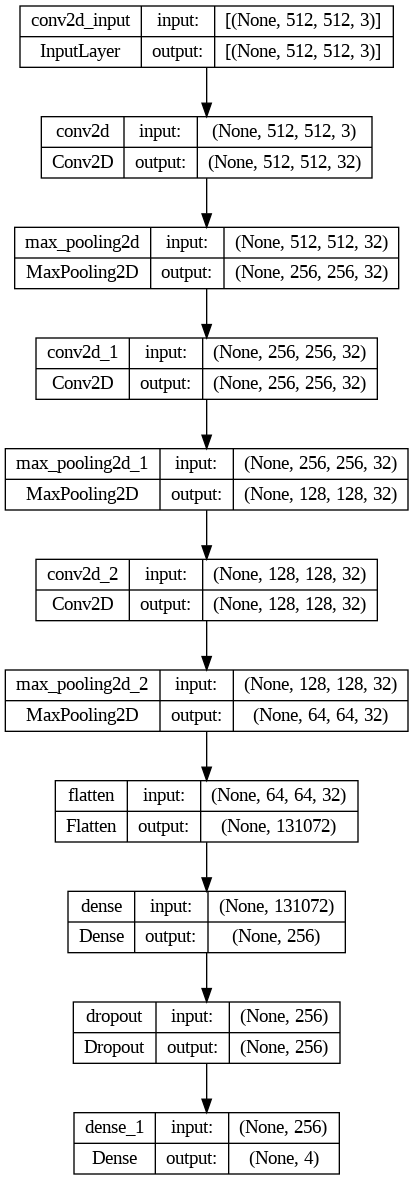

In [ ]:
from tensorflow.keras.utils import plot_model
plot_model(model, to_file='model_plot.png', show_shapes=True, show_layer_names=True)